## Imports et configuration

In [36]:
from pathlib import Path

print("Dossier actuel :", Path.cwd())

fichiers = [
    "Bank Customer Churn Prediction.csv",
    "credit_card_churn.csv"
]

for fichier in fichiers:
    if Path(fichier).is_file():
        print("OK :", fichier)
    else:
        print("INTROUVABLE :", fichier)

Dossier actuel : C:\Users\mimil\OneDrive\Desktop\PFA_Churn_Bancaire
OK : Bank Customer Churn Prediction.csv
OK : credit_card_churn.csv


# Prédiction de l'Attrition des Clients Bancaires
## Machine Learning · Deep Learning · IA Explicable (XAI)

**École Nationale des Sciences Appliquées d'Oujda (ENSAO)**  
**Université Mohammed Premier — Oujda, Maroc**  
**Année universitaire 2025–2026**

---

### Objectifs du projet

1. **Prédire** : identifier les clients susceptibles de quitter la banque
2. **Expliquer** : comprendre les raisons individuelles du départ (SHAP)
3. **Agir** : proposer des recommandations concrètes (DiCE + Playbook)

### Données utilisées

- **Dataset 1** : Bank Customer Churn (10 000 clients bancaires généraux)
- **Dataset 2** : Credit Card Churn (10 127 détenteurs de cartes de crédit)

### Plan du notebook

| Section | Contenu |
|---|---|
| 1 | Dataset 1 — Exploration des données (EDA) |
| 2 | Dataset 1 — Machine Learning (LogReg, RF, XGBoost) |
| 3 | Dataset 1 — Deep Learning (MLP) |
| 4 | Dataset 1 — XAI : SHAP + DiCE |
| 5 | Dataset 1 — Playbook de rétention |
| 6 | Dataset 2 — Exploration des données (EDA) |
| 7 | Dataset 2 — Machine Learning |
| 8 | Dataset 2 — Deep Learning |
| 9 | Dataset 2 — XAI : SHAP + DiCE |
| 10 | Dataset 2 — Playbook de rétention |


In [4]:
import os
import warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import dice_ml

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
tf.get_logger().setLevel('ERROR')

print("Toutes les bibliotheques importees avec succes !")
print("Versions :")
print(f"  pandas     : {pd.__version__}")
print(f"  scikit-learn : ok")
print(f"  tensorflow : {tf.__version__}")
print(f"  shap       : {shap.__version__}")


Toutes les bibliotheques importees avec succes !
Versions :
  pandas     : 2.2.3
  scikit-learn : ok
  tensorflow : 2.21.0
  shap       : 0.53.0


---
# PARTIE 1 : Dataset Bancaire Général
## Section 1 — Exploration des Données (EDA)

L'EDA (Exploratory Data Analysis) est la première étape de tout projet de data science.  
Elle permet de **comprendre les données**, de **détecter les anomalies**, et d'**identifier 
les variables qui influencent le churn** avant même de lancer un modèle.


In [5]:
# ============================================================
# CHARGEMENT ET VERIFICATION DES DONNEES - DATASET 1
# ============================================================

import pandas as pd

# Chargement du premier dataset
df1 = pd.read_csv("Bank Customer Churn Prediction.csv")

# Affichage des informations générales
print("=== Aperçu des données ===")
print(f"Dimensions : {df1.shape[0]} clients, {df1.shape[1]} variables")
print()

# Affichage des 5 premières lignes
display(df1.head())

=== Aperçu des données ===
Dimensions : 10000 clients, 12 variables



,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [6]:
# Verification de la qualite des donnees
print("=== Valeurs manquantes ===")
print(df1.isnull().sum())
print()
print(f"Doublons : {df1.duplicated().sum()}")
print()
print("=== Repartition du churn ===")
print(df1['churn'].value_counts(normalize=True).mul(100).round(1).astype(str) + '%')


=== Valeurs manquantes ===
customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

Doublons : 0

=== Repartition du churn ===
churn
0    79.6%
1    20.4%
Name: proportion, dtype: object


In [7]:
# Statistiques descriptives
print("=== Statistiques descriptives ===")
df1.describe().round(2)


=== Statistiques descriptives ===


,customer_id,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.0
mean,15690940.57,650.53,38.92,5.01,76485.89,1.53,0.71,0.52,100090.24,0.2
std,71936.19,96.65,10.49,2.89,62397.41,0.58,0.46,0.50,57510.49,0.4
min,15565701.00,350.00,18.00,0.00,0.00,1.00,0.00,0.00,11.58,0.0
25%,15628528.25,584.00,32.00,3.00,0.00,1.00,0.00,0.00,51002.11,0.0
50%,15690738.00,652.00,37.00,5.00,97198.54,1.00,1.00,1.00,100193.92,0.0
75%,15753233.75,718.00,44.00,7.00,127644.24,2.00,1.00,1.00,149388.25,0.0
max,15815690.00,850.00,92.00,10.00,250898.09,4.00,1.00,1.00,199992.48,1.0


In [8]:
# Analyse du churn par variables cles
df1['age_bin'] = pd.cut(df1['age'], bins=[18, 30, 40, 50, 60, 100])
churn_age      = df1.groupby('age_bin')['churn'].mean()
churn_produits = df1.groupby('products_number')['churn'].mean()
churn_activite = df1.groupby('active_member')['churn'].mean()
churn_pays     = df1.groupby('country')['churn'].mean()

print("Taux de churn par tranche d age :")
print(churn_age.apply(lambda x: f"{x*100:.1f}%"))
print()
print("Taux de churn par nombre de produits :")
print(churn_produits.apply(lambda x: f"{x*100:.1f}%"))
print()
print("Taux de churn par statut actif/inactif :")
print(churn_activite.apply(lambda x: f"{x*100:.1f}%"))
print()
print("Taux de churn par pays :")
print(churn_pays.apply(lambda x: f"{x*100:.1f}%"))


Taux de churn par tranche d age :
age_bin
(18, 30]      7.5%
(30, 40]     12.1%
(40, 50]     34.0%
(50, 60]     56.2%
(60, 100]    24.8%
Name: churn, dtype: object

Taux de churn par nombre de produits :
products_number
1     27.7%
2      7.6%
3     82.7%
4    100.0%
Name: churn, dtype: object

Taux de churn par statut actif/inactif :
active_member
0    26.9%
1    14.3%
Name: churn, dtype: object

Taux de churn par pays :
country
France     16.2%
Germany    32.4%
Spain      16.7%
Name: churn, dtype: object


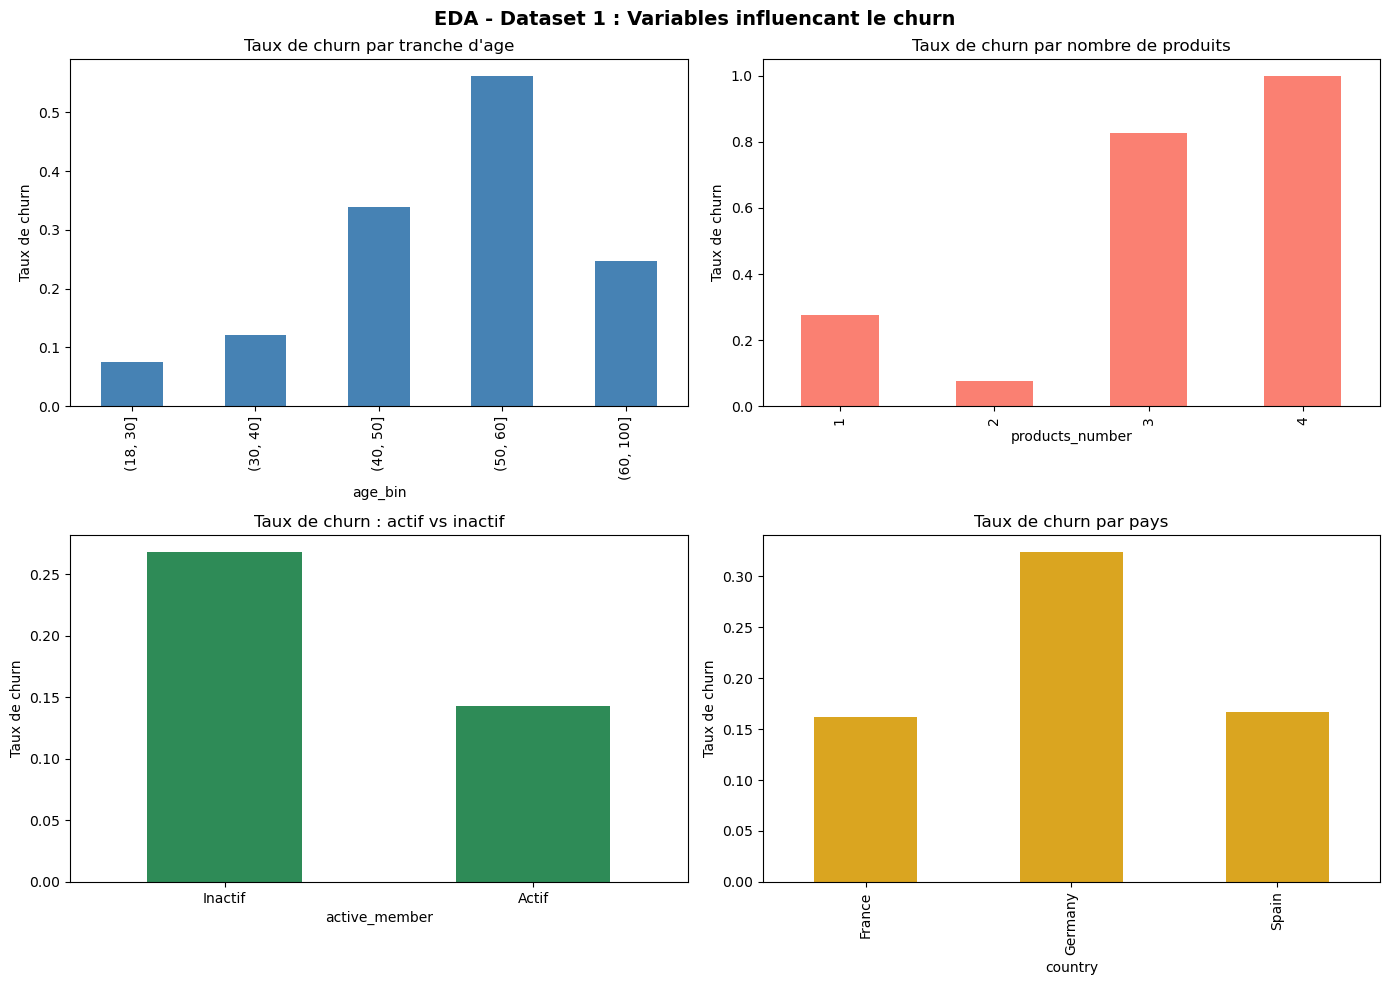

In [9]:
# Visualisations EDA - Dataset 1
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

churn_age.plot(kind='bar', ax=axes[0,0], color='steelblue')
axes[0,0].set_title("Taux de churn par tranche d'age", fontsize=12)
axes[0,0].set_ylabel("Taux de churn")

churn_produits.plot(kind='bar', ax=axes[0,1], color='salmon')
axes[0,1].set_title("Taux de churn par nombre de produits", fontsize=12)
axes[0,1].set_ylabel("Taux de churn")

churn_activite.plot(kind='bar', ax=axes[1,0], color='seagreen')
axes[1,0].set_title("Taux de churn : actif vs inactif", fontsize=12)
axes[1,0].set_xticklabels(['Inactif', 'Actif'], rotation=0)
axes[1,0].set_ylabel("Taux de churn")

churn_pays.plot(kind='bar', ax=axes[1,1], color='goldenrod')
axes[1,1].set_title("Taux de churn par pays", fontsize=12)
axes[1,1].set_ylabel("Taux de churn")

plt.suptitle("EDA - Dataset 1 : Variables influencant le churn", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


Correlation de chaque variable avec le churn :
churn                1.000
age                  0.285
balance              0.119
country              0.036
estimated_salary     0.012
credit_card         -0.007
tenure              -0.014
credit_score        -0.027
products_number     -0.048
gender              -0.107
active_member       -0.156
Name: churn, dtype: object


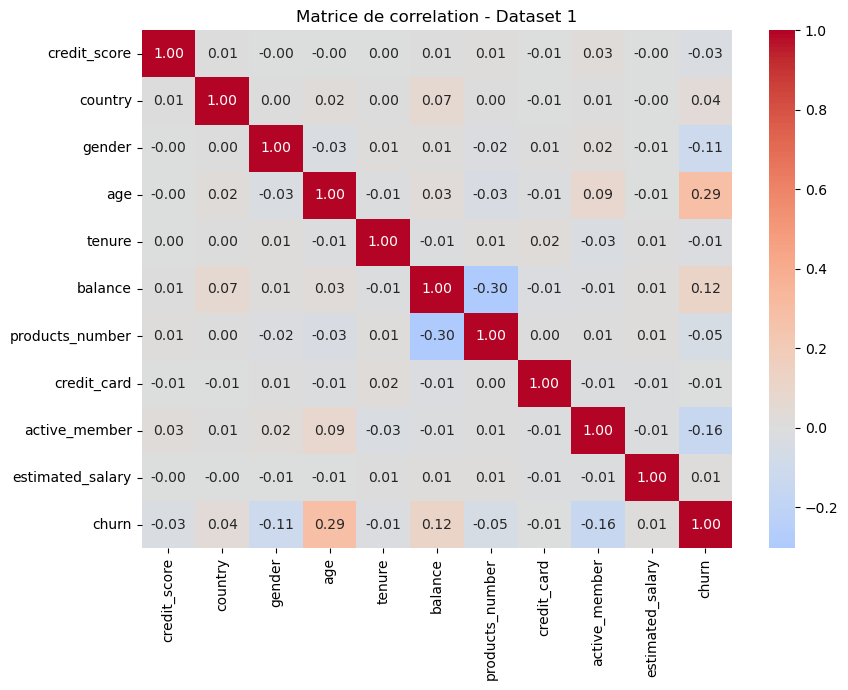

In [10]:
# Matrice de correlation - Dataset 1
df1_corr = df1.drop(columns=['age_bin']).copy()
df1_corr['country'] = LabelEncoder().fit_transform(df1_corr['country'])
df1_corr['gender']  = LabelEncoder().fit_transform(df1_corr['gender'])
df1_corr = df1_corr.drop(columns=['customer_id'])

corr1 = df1_corr.corr()['churn'].sort_values(ascending=False)
print("Correlation de chaque variable avec le churn :")
print(corr1.apply(lambda x: f"{x:.3f}"))

plt.figure(figsize=(9, 7))
sns.heatmap(df1_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de correlation - Dataset 1", fontsize=12)
plt.tight_layout()
plt.show()


---
## Section 2 — Machine Learning

Nous comparons **3 modèles** de Machine Learning sur le Dataset 1 :
- **Régression Logistique** : simple, interprétable
- **Random Forest** : robuste, vote de 100 arbres
- **XGBoost** : très performant, arbres qui corrigent les erreurs

Métrique d'évaluation : **ROC-AUC** (robuste face au déséquilibre des classes)


In [11]:
# Preparation des donnees pour le ML - Dataset 1
df1_ml = df1.drop(columns=['age_bin']).copy()
df1_ml['country'] = LabelEncoder().fit_transform(df1_ml['country'])
df1_ml['gender']  = LabelEncoder().fit_transform(df1_ml['gender'])
df1_ml = df1_ml.drop(columns=['customer_id'])

X1 = df1_ml.drop(columns=['churn'])
y1 = df1_ml['churn']

# Split train (80%) / test (20%)
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42
)

# Normalisation pour la regression logistique
scaler1 = StandardScaler()
X1_train_scaled = scaler1.fit_transform(X1_train)
X1_test_scaled  = scaler1.transform(X1_test)

print(f"Train : {X1_train.shape[0]} clients")
print(f"Test  : {X1_test.shape[0]} clients")


Train : 8000 clients
Test  : 2000 clients


In [12]:
# Modele 1 : Regression Logistique
lr1 = LogisticRegression(max_iter=2000, random_state=42)
lr1.fit(X1_train_scaled, y1_train)
auc_lr1 = roc_auc_score(y1_test, lr1.predict_proba(X1_test_scaled)[:,1])
print(f"AUC Regression Logistique : {auc_lr1:.3f}")

# Modele 2 : Random Forest
rf1 = RandomForestClassifier(n_estimators=100, random_state=42)
rf1.fit(X1_train, y1_train)
auc_rf1 = roc_auc_score(y1_test, rf1.predict_proba(X1_test)[:,1])
print(f"AUC Random Forest         : {auc_rf1:.3f}")

# Modele 3 : XGBoost
xgb1 = XGBClassifier(n_estimators=100, random_state=42, eval_metric='auc', verbosity=0)
xgb1.fit(X1_train, y1_train)
auc_xgb1 = roc_auc_score(y1_test, xgb1.predict_proba(X1_test)[:,1])
print(f"AUC XGBoost               : {auc_xgb1:.3f}")


AUC Regression Logistique : 0.764
AUC Random Forest         : 0.857
AUC XGBoost               : 0.853


               Modele   AUC
Regression Logistique 0.764
        Random Forest 0.857
              XGBoost 0.853

Meilleur modele : Random Forest


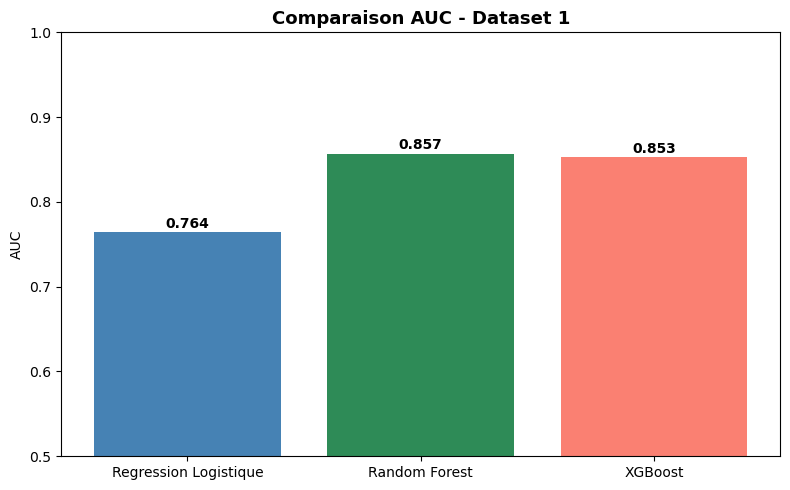

In [13]:
# Comparaison des modeles - Dataset 1
resultats1 = pd.DataFrame({
    'Modele': ['Regression Logistique', 'Random Forest', 'XGBoost'],
    'AUC'   : [round(auc_lr1,3), round(auc_rf1,3), round(auc_xgb1,3)]
})
print(resultats1.to_string(index=False))
print(f"\nMeilleur modele : {resultats1.loc[resultats1['AUC'].idxmax(), 'Modele']}")

plt.figure(figsize=(8, 5))
bars = plt.bar(resultats1['Modele'], resultats1['AUC'],
               color=['steelblue', 'seagreen', 'salmon'])
plt.title("Comparaison AUC - Dataset 1", fontsize=13, fontweight='bold')
plt.ylabel("AUC")
plt.ylim(0.5, 1.0)
for bar, v in zip(bars, resultats1['AUC']):
    plt.text(bar.get_x()+bar.get_width()/2, v+0.005, str(v),
             ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


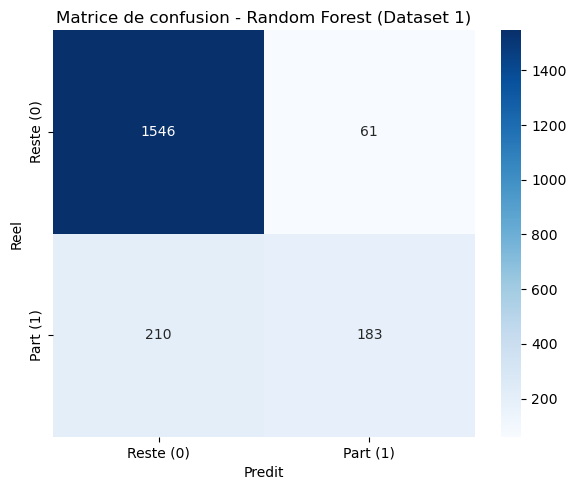


Rapport de classification :
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1607
           1       0.75      0.47      0.57       393

    accuracy                           0.86      2000
   macro avg       0.82      0.71      0.75      2000
weighted avg       0.85      0.86      0.85      2000



In [14]:
# Matrice de confusion - Meilleur modele (Random Forest)
pred_rf1 = rf1.predict(X1_test)
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y1_test, pred_rf1)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Reste (0)', 'Part (1)'],
            yticklabels=['Reste (0)', 'Part (1)'])
plt.title("Matrice de confusion - Random Forest (Dataset 1)")
plt.ylabel("Reel")
plt.xlabel("Predit")
plt.tight_layout()
plt.show()

print("\nRapport de classification :")
print(classification_report(y1_test, pred_rf1))


---
## Section 3 — Deep Learning (MLP)

Le **MLP (Multi-Layer Perceptron)** est un réseau de neurones simple adapté aux données tabulaires.  
Structure : Couche entrée → 64 neurones → Dropout → 32 neurones → Dropout → Sortie (probabilité churn)


In [15]:
# Preparation pour le MLP - normalisation obligatoire
scaler1_mlp = StandardScaler()
X1_train_mlp = scaler1_mlp.fit_transform(X1_train)
X1_test_mlp  = scaler1_mlp.transform(X1_test)

# Architecture du MLP
model1_mlp = Sequential([
    Dense(64, activation='relu', input_shape=(X1_train_mlp.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model1_mlp.compile(optimizer='adam', loss='binary_crossentropy', metrics=['AUC'])
model1_mlp.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │             704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Entrainement du MLP - Dataset 1
historique1 = model1_mlp.fit(
    X1_train_mlp, y1_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

proba_mlp1 = model1_mlp.predict(X1_test_mlp, verbose=0).flatten()
auc_mlp1   = roc_auc_score(y1_test, proba_mlp1)
print(f"\nAUC MLP (Deep Learning) Dataset 1 : {auc_mlp1:.3f}")


Epoch 1/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - AUC: 0.6444 - loss: 0.4925 - val_AUC: 0.7648 - val_loss: 0.4324
Epoch 2/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.7489 - loss: 0.4445 - val_AUC: 0.7910 - val_loss: 0.4124
Epoch 3/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.7676 - loss: 0.4316 - val_AUC: 0.8057 - val_loss: 0.3984
Epoch 4/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.7780 - loss: 0.4233 - val_AUC: 0.8173 - val_loss: 0.3870
Epoch 5/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.7978 - loss: 0.4063 - val_AUC: 0.8246 - val_loss: 0.3778
Epoch 6/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.8077 - loss: 0.3983 - val_AUC: 0.8352 - val_loss: 0.3738
Epoch 7/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.8176 - loss: 0.3877 - val_AUC: 0.8399 - val_loss: 0.3637
Epoch 8/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.8257 - loss: 0.3804 - val_AUC: 0.8438 - val_loss: 0.3616
Epoch 9/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AU

Métriques disponibles : ['AUC', 'loss', 'val_AUC', 'val_loss']


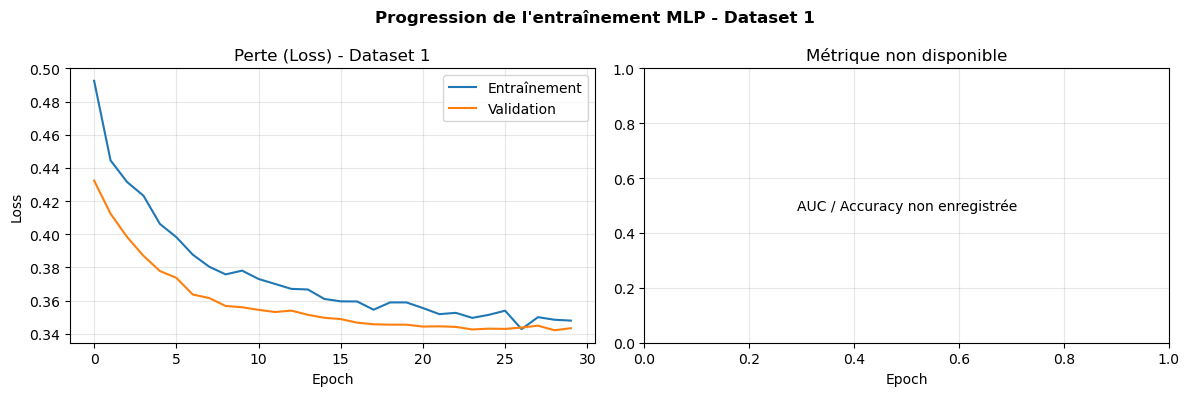


=== COMPARAISON FINALE - DATASET 1 ===
Régression Logistique : 0.764
Random Forest        : 0.857
XGBoost              : 0.853
MLP (Deep Learning)  : 0.860


In [17]:
# ============================================================
# COURBES D'APPRENTISSAGE - DATASET 1
# ============================================================

import matplotlib.pyplot as plt

history = historique1.history

print("Métriques disponibles :", list(history.keys()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1. Courbe de perte
axes[0].plot(history['loss'], label='Entraînement')

if 'val_loss' in history:
    axes[0].plot(history['val_loss'], label='Validation')

axes[0].set_title("Perte (Loss) - Dataset 1")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. Courbe AUC ou Accuracy selon les métriques disponibles
metric = None

for candidate in ['auc', 'auc_1', 'accuracy', 'binary_accuracy']:
    if candidate in history:
        metric = candidate
        break

if metric is not None:
    axes[1].plot(history[metric], label='Entraînement')

    if 'val_' + metric in history:
        axes[1].plot(history['val_' + metric], label='Validation')

    axes[1].set_title(f"{metric.upper()} - Dataset 1")
    axes[1].set_ylabel(metric.upper())
    axes[1].legend()
else:
    axes[1].text(
        0.5, 0.5,
        "AUC / Accuracy non enregistrée",
        ha='center',
        va='center',
        transform=axes[1].transAxes
    )
    axes[1].set_title("Métrique non disponible")

axes[1].set_xlabel("Epoch")
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Progression de l'entraînement MLP - Dataset 1",
    fontweight='bold'
)

plt.tight_layout()
plt.show()

# ============================================================
# COMPARAISON FINALE ML VS DL
# ============================================================

print("\n=== COMPARAISON FINALE - DATASET 1 ===")
print(f"Régression Logistique : {auc_lr1:.3f}")
print(f"Random Forest        : {auc_rf1:.3f}")
print(f"XGBoost              : {auc_xgb1:.3f}")
print(f"MLP (Deep Learning)  : {auc_mlp1:.3f}")

---
## Section 4 — XAI : SHAP + DiCE

### SHAP (SHapley Additive exPlanations)
Répond à : **"Pourquoi le modèle prédit ce churn ?"**  
Attribue à chaque variable sa part de responsabilité dans la prédiction.

### DiCE (Diverse Counterfactual Explanations)
Répond à : **"Que faudrait-il changer pour retenir ce client ?"**  
Génère des scénarios alternatifs réalistes où le client ne churnerait pas.


In [18]:
# SHAP Global - Dataset 1
# On utilise XGBoost (le plus performant avec RF)
explainer1   = shap.TreeExplainer(xgb1)
shap_values1 = explainer1.shap_values(X1_test)

# Classement global des variables par importance SHAP
importance1 = pd.DataFrame({
    'Variable'  : X1.columns,
    'SHAP moyen': np.abs(shap_values1).mean(axis=0)
}).sort_values('SHAP moyen', ascending=False)

print("Classement des variables par importance SHAP - Dataset 1 :")
print(importance1.to_string(index=False))


Classement des variables par importance SHAP - Dataset 1 :
        Variable  SHAP moyen
             age    1.038245
 products_number    0.938195
   active_member    0.516487
         balance    0.399267
estimated_salary    0.305912
          gender    0.305721
    credit_score    0.299881
         country    0.269729
          tenure    0.158295
     credit_card    0.053654


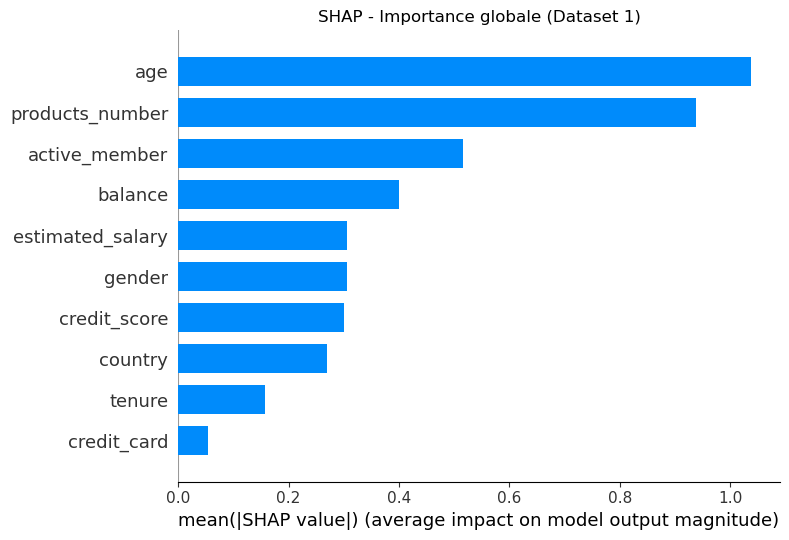

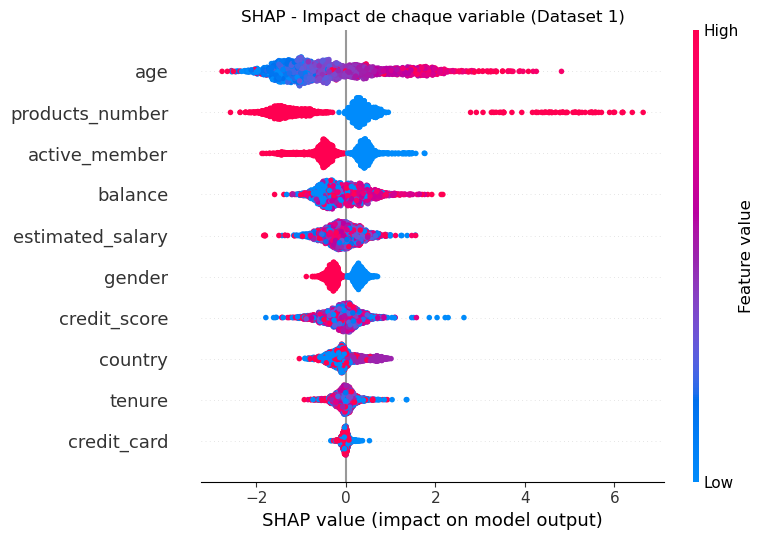

In [19]:
# Graphiques SHAP Global - Dataset 1
plt.figure(figsize=(8, 5))
shap.summary_plot(shap_values1, X1_test, plot_type="bar", show=False)
plt.title("SHAP - Importance globale (Dataset 1)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
shap.summary_plot(shap_values1, X1_test, show=False)
plt.title("SHAP - Impact de chaque variable (Dataset 1)")
plt.tight_layout()
plt.show()


Client selectionne :
      credit_score  country  gender  age  tenure  balance  products_number  credit_card  active_member  estimated_salary
7487           651        0       0   56       4      0.0                1            0              0          84383.22

Probabilite de churn : 93.9000015258789%

Contributions SHAP :
        Variable   Valeur  SHAP (contribution)
             age    56.00             3.346838
   active_member     0.00             1.035971
 products_number     1.00             0.620361
         balance     0.00             0.041573
          gender     0.00             0.032630
     credit_card     0.00            -0.002623
         country     0.00            -0.054984
    credit_score   651.00            -0.068853
estimated_salary 84383.22            -0.295100
          tenure     4.00            -0.380530


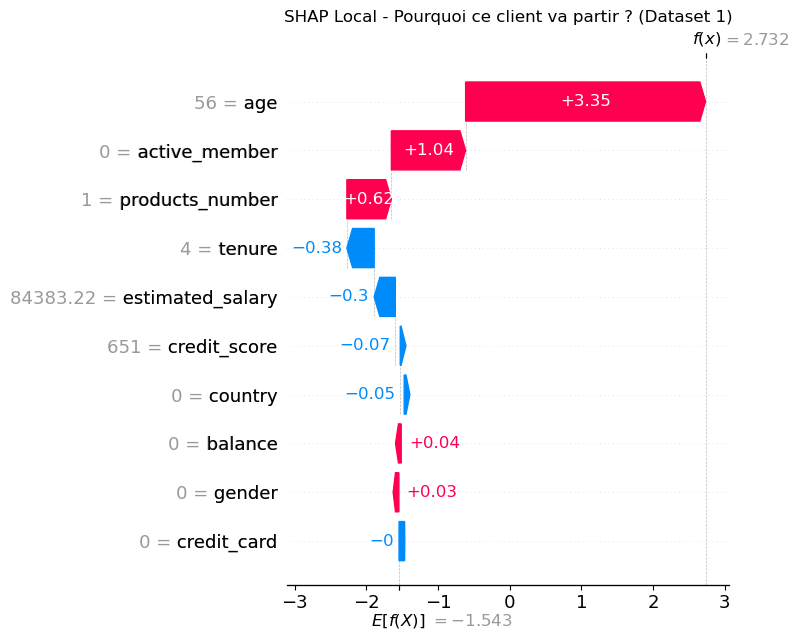

In [20]:
# SHAP Local - Explication pour un client a haut risque
probas_xgb1 = xgb1.predict_proba(X1_test)[:,1]
mask_risque1 = (probas_xgb1 > 0.6) & (probas_xgb1 < 0.99)
idx_local1   = np.where(mask_risque1)[0][0]
client1      = X1_test.iloc[[idx_local1]]

print(f"Client selectionne :")
print(client1.to_string())
print(f"\nProbabilite de churn : {round(probas_xgb1[idx_local1]*100,1)}%")

shap_client1 = explainer1.shap_values(client1)[0]

# Tableau des contributions
shap_local1 = pd.DataFrame({
    'Variable'           : X1.columns,
    'Valeur'             : client1.values[0],
    'SHAP (contribution)': shap_client1
}).sort_values('SHAP (contribution)', ascending=False)

print("\nContributions SHAP :")
print(shap_local1.to_string(index=False))

# Waterfall plot
shap_exp1 = shap.Explanation(
    values=shap_client1,
    base_values=explainer1.expected_value,
    data=client1.values[0],
    feature_names=list(X1.columns)
)
plt.figure(figsize=(8,5))
shap.waterfall_plot(shap_exp1, show=False)
plt.title("SHAP Local - Pourquoi ce client va partir ? (Dataset 1)")
plt.tight_layout()
plt.show()


In [21]:
# DiCE - Contrefactuels Dataset 1
train_df1 = X1_train.copy()
train_df1['churn'] = y1_train.values

data_dice1  = dice_ml.Data(dataframe=train_df1,
                            continuous_features=list(X1.columns),
                            outcome_name='churn')
model_dice1 = dice_ml.Model(model=xgb1, backend='sklearn')
exp_dice1   = dice_ml.Dice(data_dice1, model_dice1, method='random')

# Variables qu on peut changer
features_var1 = ['credit_score','age','tenure','balance',
                  'products_number','active_member','estimated_salary']

mask_dice1   = (probas_xgb1 > 0.6) & (probas_xgb1 < 0.95)
idx_dice1    = np.where(mask_dice1)[0][0]
client_dice1 = X1_test.iloc[[idx_dice1]]

print(f"Client selectionne pour DiCE :")
print(client_dice1.to_string())
print(f"Probabilite de churn : {round(probas_xgb1[idx_dice1]*100,1)}%")

cf1    = exp_dice1.generate_counterfactuals(client_dice1, total_CFs=3,
           desired_class='opposite', features_to_vary=features_var1)
cf_df1 = cf1.cf_examples_list[0].final_cfs_df

print("\nComparaison Situation actuelle vs Contrefactuels DiCE :")
print(f"{'Variable':<22} {'Actuel':>10} {'DiCE CF1':>12} {'Changement':>15}")
print("-"*62)
for col in features_var1:
    v_reel = round(float(client_dice1[col].values[0]),2)
    v_cf   = round(float(cf_df1[col].values[0]),2)
    chg    = "*** CHANGER ***" if v_reel != v_cf else "inchange"
    print(f"{col:<22} {v_reel:>10} {v_cf:>12} {chg:>15}")


Client selectionne pour DiCE :
      credit_score  country  gender  age  tenure  balance  products_number  credit_card  active_member  estimated_salary
7487           651        0       0   56       4      0.0                1            0              0          84383.22
Probabilite de churn : 93.9000015258789%


100%|████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.66it/s]


Comparaison Situation actuelle vs Contrefactuels DiCE :
Variable                   Actuel     DiCE CF1      Changement
--------------------------------------------------------------
credit_score                651.0        823.0 *** CHANGER ***
age                          56.0         80.0 *** CHANGER ***
tenure                        4.0          4.0        inchange
balance                       0.0          0.0        inchange
products_number               1.0          1.0        inchange
active_member                 0.0          0.0        inchange
estimated_salary         84383.22     84383.22        inchange


---
## Section 5 — Playbook de Rétention (Dataset 1)

Le playbook transforme les résultats ML/XAI en **recommandations concrètes et chiffrées**  
adaptées au **contexte bancaire marocain** (Attijariwafa, CIH, Banque Populaire...).  
Monnaie : **Dirham Marocain (MAD)**


In [22]:
# Segmentation des clients a risque - Dataset 1
df_play1 = X1_test.copy()
df_play1['proba_churn'] = probas_xgb1

# Segment 1 : Client age avec trop de produits
seg1 = df_play1[(df_play1['age'] > 40) &
                (df_play1['products_number'] >= 3) &
                (df_play1['proba_churn'] > 0.6)].copy()

# Segment 2 : Client inactif
seg2 = df_play1[(df_play1['active_member'] == 0) &
                (df_play1['proba_churn'] > 0.4) &
                (~df_play1.index.isin(seg1.index))].copy()

# Segment 3 : Client fortune a risque modere
seg3 = df_play1[(df_play1['balance'] > 50000) &
                (df_play1['proba_churn'] > 0.3) &
                (df_play1['proba_churn'] <= 0.6) &
                (~df_play1.index.isin(seg1.index)) &
                (~df_play1.index.isin(seg2.index))].copy()

print(f"Segment 1 - Premium Surcharge          : {len(seg1)} clients")
print(f"Segment 2 - Client Inactif              : {len(seg2)} clients")
print(f"Segment 3 - Client Fortune Risque Modere: {len(seg3)} clients")
print(f"Total                                   : {len(seg1)+len(seg2)+len(seg3)} clients")


Segment 1 - Premium Surcharge          : 38 clients
Segment 2 - Client Inactif              : 205 clients
Segment 3 - Client Fortune Risque Modere: 108 clients
Total                                   : 351 clients


In [23]:
# Playbook final - Dataset 1 (contexte marocain)
playbook1 = pd.DataFrame([
    {
        'Segment'            : '1 - Premium Surcharge',
        'Profil'             : 'Age > 40 ans, 3-4 produits, risque > 60%',
        'Nb clients'         : len(seg1),
        'Risque moyen'       : f"{round(seg1['proba_churn'].mean()*100,1)}%",
        'Action'             : 'Appel conseiller + simplification (reduire nb produits)',
        'Canal'              : 'Appel + visite agence',
        'Justification DiCE' : 'DiCE suggere de reduire products_number de 3 a 2',
        'Cout/client (MAD)'  : '15 MAD',
        'Cout total (MAD)'   : f"{len(seg1)*15} MAD"
    },
    {
        'Segment'            : '2 - Client Inactif',
        'Profil'             : 'Membre inactif, risque > 40%',
        'Nb clients'         : len(seg2),
        'Risque moyen'       : f"{round(seg2['proba_churn'].mean()*100,1)}%",
        'Action'             : 'SMS de reactivation + offre cashback',
        'Canal'              : 'SMS / WhatsApp / Email',
        'Justification DiCE' : 'DiCE suggere d augmenter l activite',
        'Cout/client (MAD)'  : '2 MAD',
        'Cout total (MAD)'   : f"{len(seg2)*2} MAD"
    },
    {
        'Segment'            : '3 - Client Fortune Risque Modere',
        'Profil'             : 'Solde > 50 000 MAD, risque 30-60%',
        'Nb clients'         : len(seg3),
        'Risque moyen'       : f"{round(seg3['proba_churn'].mean()*100,1)}%",
        'Action'             : 'Invitation VIP + renegociation conditions bancaires',
        'Canal'              : 'Appel directeur agence + RDV personnalise',
        'Justification DiCE' : 'DiCE suggere d augmenter l anciennete et l engagement',
        'Cout/client (MAD)'  : '50 MAD',
        'Cout total (MAD)'   : f"{len(seg3)*50} MAD"
    }
])

print("=== PLAYBOOK DE RETENTION - DATASET 1 (Contexte Marocain) ===\n")
for _, row in playbook1.iterrows():
    print(f"--- {row['Segment']} ---")
    for col in playbook1.columns[1:]:
        print(f"  {col:<22}: {row[col]}")
    print()

cout_total1 = len(seg1)*15 + len(seg2)*2 + len(seg3)*50
print(f"BUDGET TOTAL CAMPAGNE : {cout_total1} MAD")


=== PLAYBOOK DE RETENTION - DATASET 1 (Contexte Marocain) ===

--- 1 - Premium Surcharge ---
  Profil                : Age > 40 ans, 3-4 produits, risque > 60%
  Nb clients            : 38
  Risque moyen          : 97.80000305175781%
  Action                : Appel conseiller + simplification (reduire nb produits)
  Canal                 : Appel + visite agence
  Justification DiCE    : DiCE suggere de reduire products_number de 3 a 2
  Cout/client (MAD)     : 15 MAD
  Cout total (MAD)      : 570 MAD

--- 2 - Client Inactif ---
  Profil                : Membre inactif, risque > 40%
  Nb clients            : 205
  Risque moyen          : 72.5%
  Action                : SMS de reactivation + offre cashback
  Canal                 : SMS / WhatsApp / Email
  Justification DiCE    : DiCE suggere d augmenter l activite
  Cout/client (MAD)     : 2 MAD
  Cout total (MAD)      : 410 MAD

--- 3 - Client Fortune Risque Modere ---
  Profil                : Solde > 50 000 MAD, risque 30-60%
  Nb cl

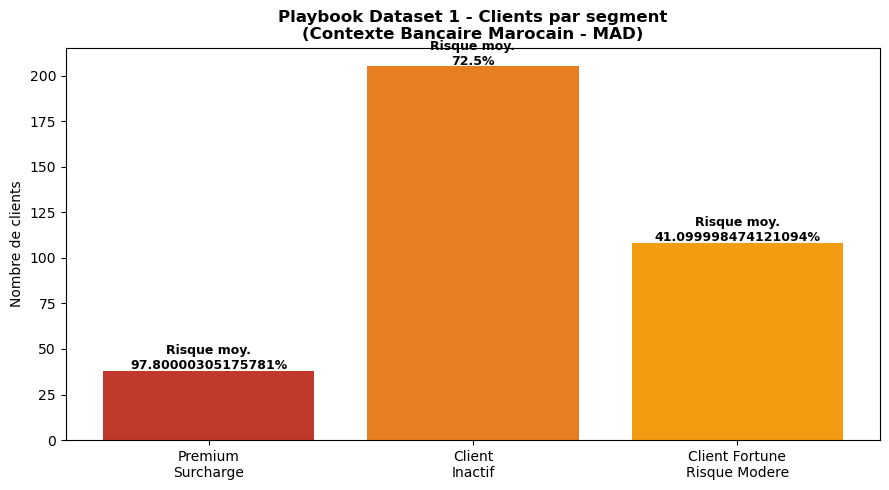

In [24]:
# Graphique playbook Dataset 1
segments1 = ['Premium\nSurcharge', 'Client\nInactif', 'Client Fortune\nRisque Modere']
nb1       = [len(seg1), len(seg2), len(seg3)]
risque1   = [round(seg1['proba_churn'].mean()*100,1),
             round(seg2['proba_churn'].mean()*100,1),
             round(seg3['proba_churn'].mean()*100,1)]

plt.figure(figsize=(9, 5))
bars = plt.bar(segments1, nb1, color=['#c0392b','#e67e22','#f39c12'])
plt.title("Playbook Dataset 1 - Clients par segment\n(Contexte Bancaire Marocain - MAD)",
          fontsize=12, fontweight='bold')
plt.ylabel("Nombre de clients")
for bar, r in zip(bars, risque1):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+1,
             f"Risque moy.\n{r}%", ha='center', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()


---
# PARTIE 2 : Dataset Cartes de Crédit
## Section 6 — Exploration des Données (EDA)


In [25]:
# Chargement et nettoyage - Dataset 2
df2 = pd.read_csv("credit_card_churn.csv")

cols_drop = [
    'CLIENTNUM',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'
]
df2 = df2.drop(columns=cols_drop)
df2['churn'] = (df2['Attrition_Flag'] == 'Attrited Customer').astype(int)
df2 = df2.drop(columns=['Attrition_Flag'])

print(f"Dimensions : {df2.shape[0]} clients, {df2.shape[1]} variables")
print()
print("Valeurs manquantes :")
print(df2.isnull().sum())
print()
print("Repartition du churn :")
print(df2['churn'].value_counts(normalize=True).mul(100).round(1).astype(str) + '%')


Dimensions : 10127 clients, 20 variables

Valeurs manquantes :
Customer_Age                0
Gender                      0
Dependent_count             0
Education_Level             0
Marital_Status              0
Income_Category             0
Card_Category               0
Months_on_book              0
Total_Relationship_Count    0
Months_Inactive_12_mon      0
Contacts_Count_12_mon       0
Credit_Limit                0
Total_Revolving_Bal         0
Avg_Open_To_Buy             0
Total_Amt_Chng_Q4_Q1        0
Total_Trans_Amt             0
Total_Trans_Ct              0
Total_Ct_Chng_Q4_Q1         0
Avg_Utilization_Ratio       0
churn                       0
dtype: int64

Repartition du churn :
churn
0    83.9%
1    16.1%
Name: proportion, dtype: object


In [26]:
# Comparaison fideles vs partis - Dataset 2
colonnes_num2 = ['Total_Trans_Ct','Total_Trans_Amt','Total_Revolving_Bal',
                  'Total_Relationship_Count','Months_Inactive_12_mon',
                  'Contacts_Count_12_mon','Customer_Age']

comparaison2 = df2.groupby('churn')[colonnes_num2].mean().T
comparaison2.columns = ['Clients fideles (0)', 'Clients partis (1)']
comparaison2['Difference'] = (comparaison2['Clients partis (1)'] - 
                               comparaison2['Clients fideles (0)']).round(2)
print("Comparaison des moyennes fideles vs partis :")
print(comparaison2.round(2))


Comparaison des moyennes fideles vs partis :
                          Clients fideles (0)  Clients partis (1)  Difference
Total_Trans_Ct                          68.67               44.93      -23.74
Total_Trans_Amt                       4654.66             3095.03    -1559.63
Total_Revolving_Bal                   1256.60              672.82     -583.78
Total_Relationship_Count                 3.91                3.28       -0.63
Months_Inactive_12_mon                   2.27                2.69        0.42
Contacts_Count_12_mon                    2.36                2.97        0.62
Customer_Age                            46.26               46.66        0.40


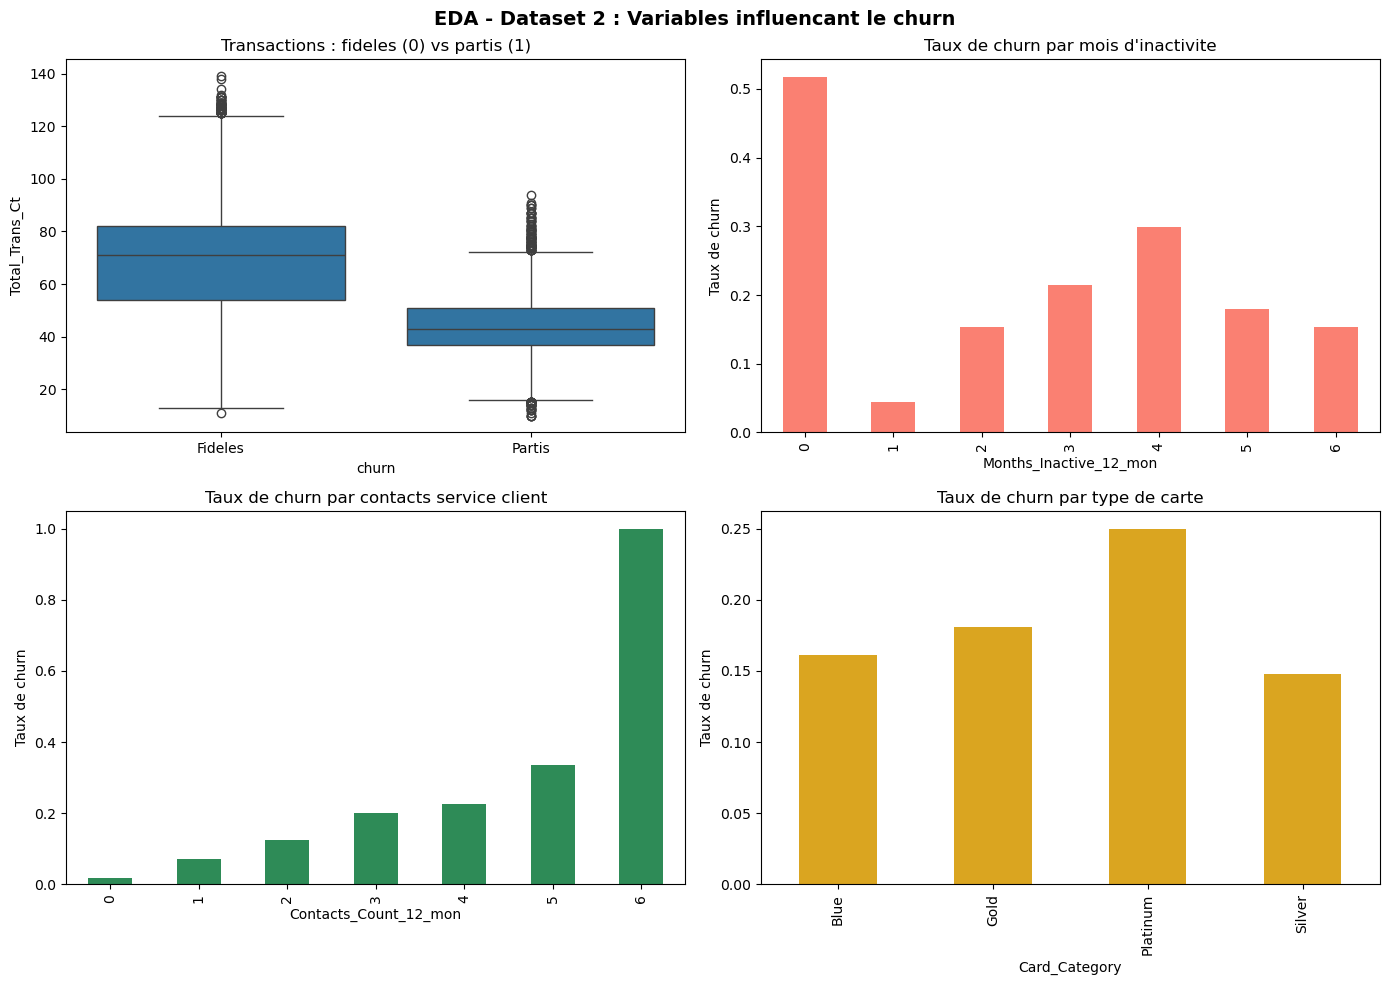

In [27]:
# Analyses par variable - Dataset 2
churn_inact = df2.groupby('Months_Inactive_12_mon')['churn'].mean()
churn_cont  = df2.groupby('Contacts_Count_12_mon')['churn'].mean()
churn_carte = df2.groupby('Card_Category')['churn'].mean()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=df2, x='churn', y='Total_Trans_Ct', ax=axes[0,0])
axes[0,0].set_title("Transactions : fideles (0) vs partis (1)")
axes[0,0].set_xticks([0,1])
axes[0,0].set_xticklabels(['Fideles','Partis'])

churn_inact.plot(kind='bar', ax=axes[0,1], color='salmon')
axes[0,1].set_title("Taux de churn par mois d'inactivite")
axes[0,1].set_ylabel("Taux de churn")

churn_cont.plot(kind='bar', ax=axes[1,0], color='seagreen')
axes[1,0].set_title("Taux de churn par contacts service client")
axes[1,0].set_ylabel("Taux de churn")

churn_carte.plot(kind='bar', ax=axes[1,1], color='goldenrod')
axes[1,1].set_title("Taux de churn par type de carte")
axes[1,1].set_ylabel("Taux de churn")

plt.suptitle("EDA - Dataset 2 : Variables influencant le churn", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


---
## Section 7 — Machine Learning (Dataset 2)

In [28]:
# Preparation ML - Dataset 2
df2_ml = df2.copy()
for col in [c for c in df2_ml.columns if pd.api.types.is_string_dtype(df2_ml[c])]:
    df2_ml[col] = LabelEncoder().fit_transform(df2_ml[col])

X2 = df2_ml.drop(columns=['churn'])
y2 = df2_ml['churn']

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled  = scaler2.transform(X2_test)

print(f"Train : {X2_train.shape[0]} clients")
print(f"Test  : {X2_test.shape[0]} clients")


Train : 8101 clients
Test  : 2026 clients


               Modele   AUC
Regression Logistique 0.916
        Random Forest 0.989
              XGBoost 0.992

Meilleur modele : XGBoost


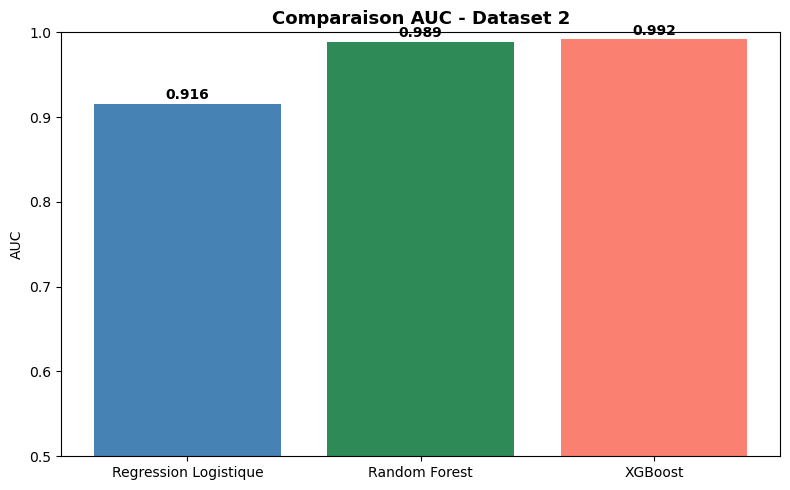

In [29]:
# Les 3 modeles ML - Dataset 2
lr2 = LogisticRegression(max_iter=2000, random_state=42)
lr2.fit(X2_train_scaled, y2_train)
auc_lr2 = roc_auc_score(y2_test, lr2.predict_proba(X2_test_scaled)[:,1])

rf2 = RandomForestClassifier(n_estimators=100, random_state=42)
rf2.fit(X2_train, y2_train)
auc_rf2 = roc_auc_score(y2_test, rf2.predict_proba(X2_test)[:,1])

xgb2 = XGBClassifier(n_estimators=100, random_state=42, eval_metric='auc', verbosity=0)
xgb2.fit(X2_train, y2_train)
auc_xgb2 = roc_auc_score(y2_test, xgb2.predict_proba(X2_test)[:,1])

resultats2 = pd.DataFrame({
    'Modele': ['Regression Logistique','Random Forest','XGBoost'],
    'AUC'   : [round(auc_lr2,3), round(auc_rf2,3), round(auc_xgb2,3)]
})
print(resultats2.to_string(index=False))
print(f"\nMeilleur modele : {resultats2.loc[resultats2['AUC'].idxmax(),'Modele']}")

plt.figure(figsize=(8,5))
bars = plt.bar(resultats2['Modele'], resultats2['AUC'],
               color=['steelblue','seagreen','salmon'])
plt.title("Comparaison AUC - Dataset 2", fontsize=13, fontweight='bold')
plt.ylabel("AUC")
plt.ylim(0.5, 1.0)
for bar, v in zip(bars, resultats2['AUC']):
    plt.text(bar.get_x()+bar.get_width()/2, v+0.005, str(v),
             ha='center', fontweight='bold')
plt.tight_layout()
plt.show()


---
## Section 8 — Deep Learning (Dataset 2)

In [30]:
# MLP - Dataset 2
scaler2_mlp  = StandardScaler()
X2_train_mlp = scaler2_mlp.fit_transform(X2_train)
X2_test_mlp  = scaler2_mlp.transform(X2_test)

model2_mlp = Sequential([
    Dense(64, activation='relu', input_shape=(X2_train_mlp.shape[1],)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])
model2_mlp.compile(optimizer='adam', loss='binary_crossentropy', metrics=['AUC'])

historique2 = model2_mlp.fit(
    X2_train_mlp, y2_train,
    epochs=30, batch_size=32,
    validation_split=0.2, verbose=1
)

proba_mlp2 = model2_mlp.predict(X2_test_mlp, verbose=0).flatten()
auc_mlp2   = roc_auc_score(y2_test, proba_mlp2)
print(f"\nAUC MLP (Deep Learning) Dataset 2 : {auc_mlp2:.3f}")

print("\n=== COMPARAISON FINALE - DATASET 2 ===")
print(f"Regression Logistique : {auc_lr2:.3f}")
print(f"Random Forest         : {auc_rf2:.3f}")
print(f"XGBoost               : {auc_xgb2:.3f}")
print(f"MLP (Deep Learning)   : {auc_mlp2:.3f}")


Epoch 1/30
203/203 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - AUC: 0.7289 - loss: 0.4029 - val_AUC: 0.8817 - val_loss: 0.2727
Epoch 2/30
203/203 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.8802 - loss: 0.2862 - val_AUC: 0.9035 - val_loss: 0.2469
Epoch 3/30
203/203 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.8968 - loss: 0.2661 - val_AUC: 0.9213 - val_loss: 0.2275
Epoch 4/30
203/203 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.9169 - loss: 0.2446 - val_AUC: 0.9325 - val_loss: 0.2134
Epoch 5/30
203/203 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.9275 - loss: 0.2338 - val_AUC: 0.9393 - val_loss: 0.2035
Epoch 6/30
203/203 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.9404 - loss: 0.2129 - val_AUC: 0.9466 - val_loss: 0.1906
Epoch 7/30
203/203 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.9476 - loss: 0.2000 - val_AUC: 0.9522 - val_loss: 0.1835
Epoch 8/30
203/203 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.9493 - loss: 0.1968 - val_AUC: 0.9553 - val_loss: 0.1775
Epoch 9/30
203/203 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AU

---
## Section 9 — XAI : SHAP + DiCE (Dataset 2)

Classement SHAP - Dataset 2 :
                Variable  SHAP moyen
          Total_Trans_Ct    3.175557
         Total_Trans_Amt    2.296863
     Total_Revolving_Bal    1.131003
    Total_Amt_Chng_Q4_Q1    0.769071
Total_Relationship_Count    0.621779
     Total_Ct_Chng_Q4_Q1    0.618282
  Months_Inactive_12_mon    0.522036
   Contacts_Count_12_mon    0.433679
            Customer_Age    0.355807
         Avg_Open_To_Buy    0.225534


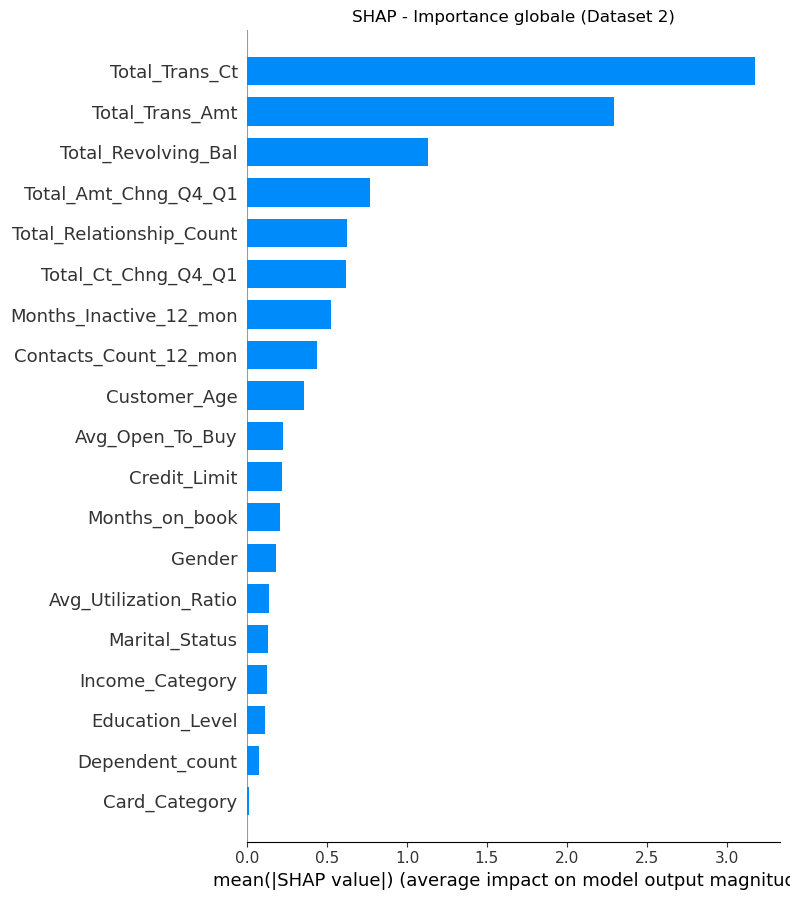

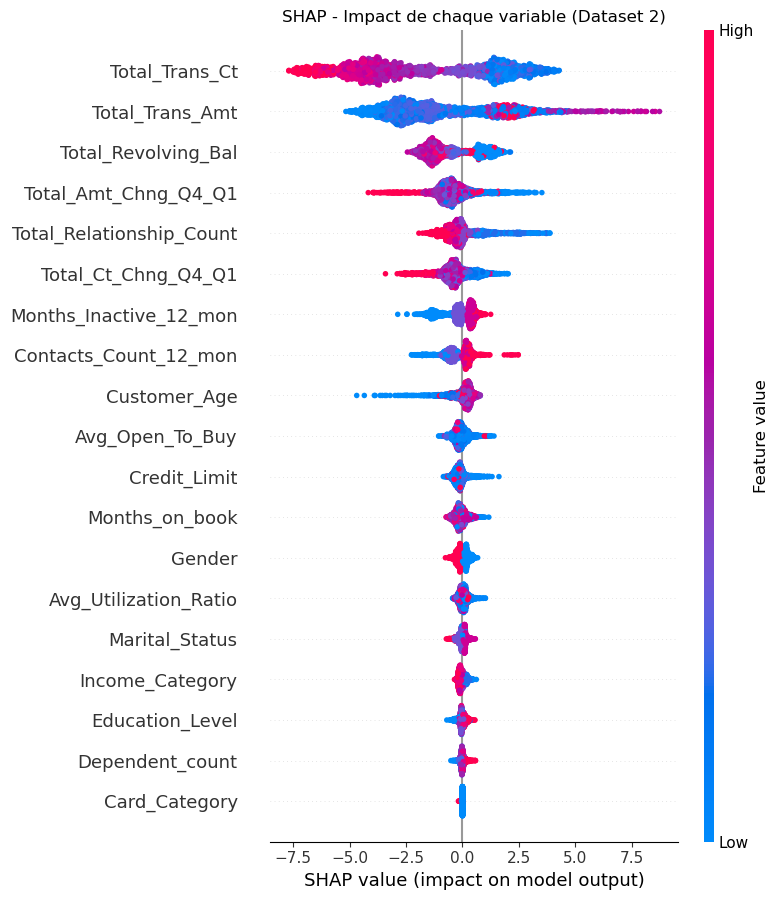

In [31]:
# SHAP Global - Dataset 2
explainer2   = shap.TreeExplainer(xgb2)
shap_values2 = explainer2.shap_values(X2_test)

importance2 = pd.DataFrame({
    'Variable'  : X2.columns,
    'SHAP moyen': np.abs(shap_values2).mean(axis=0)
}).sort_values('SHAP moyen', ascending=False)

print("Classement SHAP - Dataset 2 :")
print(importance2.head(10).to_string(index=False))

plt.figure(figsize=(10,6))
shap.summary_plot(shap_values2, X2_test, plot_type="bar", show=False)
plt.title("SHAP - Importance globale (Dataset 2)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,6))
shap.summary_plot(shap_values2, X2_test, show=False)
plt.title("SHAP - Impact de chaque variable (Dataset 2)")
plt.tight_layout()
plt.show()


Probabilite de churn du client : 90.5%

Contributions SHAP :
              Variable   Valeur  SHAP (contribution)
       Total_Trans_Amt 2579.000             3.394240
        Total_Trans_Ct   47.000             2.275744
       Avg_Open_To_Buy  340.000             0.650201
   Total_Ct_Chng_Q4_Q1    0.469             0.479229
          Credit_Limit 1876.000             0.457234
Months_Inactive_12_mon    3.000             0.438049
                Gender    0.000             0.437873
        Marital_Status    2.000             0.156720


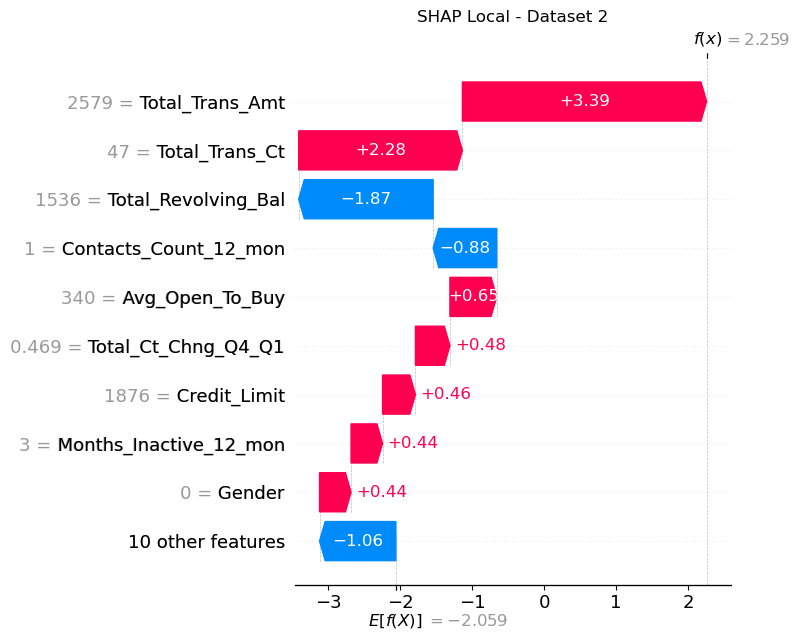

100%|████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.46it/s]


DiCE - Client avec 90.5% de risque :
Variable                           Actuel     DiCE CF1      Changement
----------------------------------------------------------------------
Total_Trans_Ct                       47.0         47.0        inchange
Total_Trans_Amt                    2579.0       2099.0 *** CHANGER ***
Total_Revolving_Bal                1536.0       1536.0        inchange
Total_Relationship_Count              3.0          3.0        inchange
Months_Inactive_12_mon                3.0          3.0        inchange
Contacts_Count_12_mon                 1.0          1.0        inchange
Total_Ct_Chng_Q4_Q1                  0.47         0.47        inchange


In [32]:
# SHAP Local + DiCE - Dataset 2
probas_xgb2 = xgb2.predict_proba(X2_test)[:,1]

# SHAP local
mask_local2 = (probas_xgb2 > 0.6) & (probas_xgb2 < 0.99)
idx_local2  = np.where(mask_local2)[0][0]
client2     = X2_test.iloc[[idx_local2]]

shap_client2 = explainer2.shap_values(client2)[0]
shap_local2  = pd.DataFrame({
    'Variable'           : X2.columns,
    'Valeur'             : client2.values[0],
    'SHAP (contribution)': shap_client2
}).sort_values('SHAP (contribution)', ascending=False)

print(f"Probabilite de churn du client : {round(probas_xgb2[idx_local2]*100,1)}%")
print("\nContributions SHAP :")
print(shap_local2.head(8).to_string(index=False))

shap_exp2 = shap.Explanation(
    values=shap_client2,
    base_values=explainer2.expected_value,
    data=client2.values[0],
    feature_names=list(X2.columns)
)
plt.figure(figsize=(10,5))
shap.waterfall_plot(shap_exp2, show=False)
plt.title("SHAP Local - Dataset 2")
plt.tight_layout()
plt.show()

# DiCE
features_var2 = ['Total_Trans_Ct','Total_Trans_Amt','Total_Revolving_Bal',
                  'Total_Relationship_Count','Months_Inactive_12_mon',
                  'Contacts_Count_12_mon','Total_Ct_Chng_Q4_Q1']

train_df2 = X2_train.copy()
train_df2['churn'] = y2_train.values

data_dice2  = dice_ml.Data(dataframe=train_df2,
                            continuous_features=list(X2.columns),
                            outcome_name='churn')
model_dice2 = dice_ml.Model(model=xgb2, backend='sklearn')
exp_dice2   = dice_ml.Dice(data_dice2, model_dice2, method='random')

mask_dice2   = (probas_xgb2 > 0.6) & (probas_xgb2 < 0.95)
idx_dice2    = np.where(mask_dice2)[0][0]
client_dice2 = X2_test.iloc[[idx_dice2]]

cf2    = exp_dice2.generate_counterfactuals(client_dice2, total_CFs=3,
           desired_class='opposite', features_to_vary=features_var2)
cf_df2 = cf2.cf_examples_list[0].final_cfs_df

print(f"\nDiCE - Client avec {round(probas_xgb2[idx_dice2]*100,1)}% de risque :")
print(f"{'Variable':<30} {'Actuel':>10} {'DiCE CF1':>12} {'Changement':>15}")
print("-"*70)
for col in features_var2:
    v_reel = round(float(client_dice2[col].values[0]),2)
    v_cf   = round(float(cf_df2[col].values[0]),2)
    chg    = "*** CHANGER ***" if v_reel != v_cf else "inchange"
    print(f"{col:<30} {v_reel:>10} {v_cf:>12} {chg:>15}")


---
## Section 10 — Playbook de Rétention (Dataset 2)

In [33]:
# Segmentation - Dataset 2
df_play2 = X2_test.copy()
df_play2['proba_churn'] = probas_xgb2

seg_a = df_play2[(df_play2['Total_Trans_Ct'] < 50) &
                  (df_play2['Months_Inactive_12_mon'] >= 3) &
                  (df_play2['proba_churn'] > 0.5)].copy()

seg_b = df_play2[(df_play2['Contacts_Count_12_mon'] >= 4) &
                  (df_play2['proba_churn'] > 0.5) &
                  (~df_play2.index.isin(seg_a.index))].copy()

seg_c = df_play2[(df_play2['Total_Trans_Ct'] < 40) &
                  (df_play2['Total_Revolving_Bal'] < 500) &
                  (df_play2['proba_churn'] > 0.6) &
                  (~df_play2.index.isin(seg_a.index)) &
                  (~df_play2.index.isin(seg_b.index))].copy()

print(f"Segment A - Carte Sous-utilisee : {len(seg_a)} clients")
print(f"Segment B - Client Frustre      : {len(seg_b)} clients")
print(f"Segment C - Desengagement Total : {len(seg_c)} clients")
print(f"Total                           : {len(seg_a)+len(seg_b)+len(seg_c)} clients")


Segment A - Carte Sous-utilisee : 124 clients
Segment B - Client Frustre      : 55 clients
Segment C - Desengagement Total : 20 clients
Total                           : 199 clients


In [34]:
# Playbook final - Dataset 2
playbook2 = pd.DataFrame([
    {
        'Segment'           : 'A - Carte Sous-utilisee',
        'Profil'            : '< 50 transactions/an, 3+ mois inactif, risque > 50%',
        'Nb clients'        : len(seg_a),
        'Risque moyen'      : f"{round(seg_a['proba_churn'].mean()*100,1)}%",
        'Action'            : 'Campagne reactivation : cashback 2% sur 3 mois',
        'Canal'             : 'SMS / Notification app mobile',
        'Justification DiCE': 'DiCE suggere d augmenter Total_Trans_Ct',
        'Cout/client (MAD)' : '10 MAD',
        'Cout total (MAD)'  : f"{len(seg_a)*10} MAD"
    },
    {
        'Segment'           : 'B - Client Frustre',
        'Profil'            : '4+ contacts service client/an, risque > 50%',
        'Nb clients'        : len(seg_b),
        'Risque moyen'      : f"{round(seg_b['proba_churn'].mean()*100,1)}%",
        'Action'            : 'Appel proactif pour resoudre les problemes signales',
        'Canal'             : 'Appel telephonique dans les 48h',
        'Justification DiCE': 'DiCE suggere de reduire Contacts_Count',
        'Cout/client (MAD)' : '20 MAD',
        'Cout total (MAD)'  : f"{len(seg_b)*20} MAD"
    },
    {
        'Segment'           : 'C - Desengagement Total',
        'Profil'            : '< 40 transactions, solde < 500 MAD, risque > 60%',
        'Nb clients'        : len(seg_c),
        'Risque moyen'      : f"{round(seg_c['proba_churn'].mean()*100,1)}%",
        'Action'            : 'Offre fidelite : frais annuels offerts + plafond augmente',
        'Canal'             : 'Courrier + appel conseiller senior',
        'Justification DiCE': 'DiCE suggere d augmenter Total_Trans_Ct et Revolving_Bal',
        'Cout/client (MAD)' : '100 MAD',
        'Cout total (MAD)'  : f"{len(seg_c)*100} MAD"
    }
])

print("=== PLAYBOOK DE RETENTION - DATASET 2 (Contexte Marocain) ===\n")
for _, row in playbook2.iterrows():
    print(f"--- {row['Segment']} ---")
    for col in playbook2.columns[1:]:
        print(f"  {col:<22}: {row[col]}")
    print()

cout_total2 = len(seg_a)*10 + len(seg_b)*20 + len(seg_c)*100
print(f"BUDGET TOTAL CAMPAGNE : {cout_total2} MAD")


=== PLAYBOOK DE RETENTION - DATASET 2 (Contexte Marocain) ===

--- A - Carte Sous-utilisee ---
  Profil                : < 50 transactions/an, 3+ mois inactif, risque > 50%
  Nb clients            : 124
  Risque moyen          : 95.30000305175781%
  Action                : Campagne reactivation : cashback 2% sur 3 mois
  Canal                 : SMS / Notification app mobile
  Justification DiCE    : DiCE suggere d augmenter Total_Trans_Ct
  Cout/client (MAD)     : 10 MAD
  Cout total (MAD)      : 1240 MAD

--- B - Client Frustre ---
  Profil                : 4+ contacts service client/an, risque > 50%
  Nb clients            : 55
  Risque moyen          : 88.80000305175781%
  Action                : Appel proactif pour resoudre les problemes signales
  Canal                 : Appel telephonique dans les 48h
  Justification DiCE    : DiCE suggere de reduire Contacts_Count
  Cout/client (MAD)     : 20 MAD
  Cout total (MAD)      : 1100 MAD

--- C - Desengagement Total ---
  Profil       

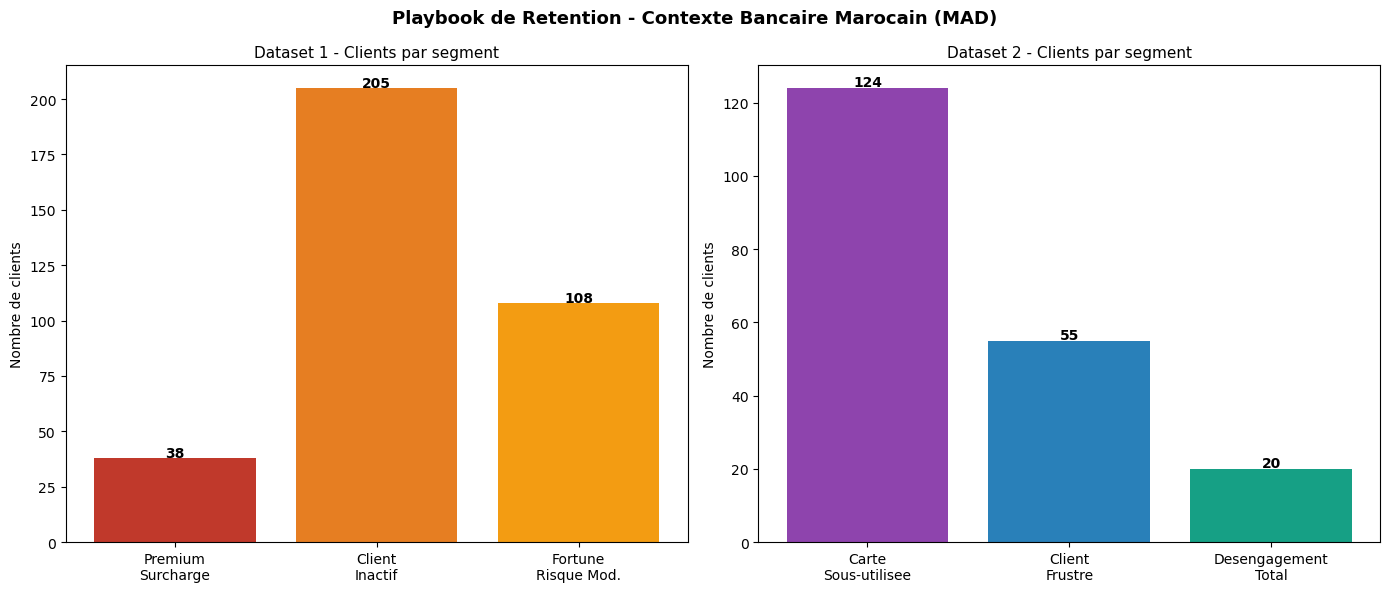


=== RESUME FINAL ===
Dataset 1 : 351 clients identifies | Budget : 6380 MAD
Dataset 2 : 199 clients identifies | Budget : 4340 MAD
Budget global des deux campagnes : 10720 MAD

Canaux privilegies au Maroc :
  SMS/WhatsApp : rapide, peu couteux, taux ouverture eleve
  Appel conseiller : efficace pour clients premium
  Application mobile : notifications push gratuites
  Agence physique : pour clients VIP (solde > 50 000 MAD)


In [35]:
# Graphique comparatif final - Les 2 datasets
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

segments1 = ['Premium\nSurcharge', 'Client\nInactif', 'Fortune\nRisque Mod.']
nb1_play  = [len(seg1), len(seg2), len(seg3)]
bars1 = axes[0].bar(segments1, nb1_play, color=['#c0392b','#e67e22','#f39c12'])
axes[0].set_title("Dataset 1 - Clients par segment", fontsize=11)
axes[0].set_ylabel("Nombre de clients")
for bar in bars1:
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                 str(int(bar.get_height())), ha='center', fontweight='bold')

segments2 = ['Carte\nSous-utilisee', 'Client\nFrustre', 'Desengagement\nTotal']
nb2_play  = [len(seg_a), len(seg_b), len(seg_c)]
bars2 = axes[1].bar(segments2, nb2_play, color=['#8e44ad','#2980b9','#16a085'])
axes[1].set_title("Dataset 2 - Clients par segment", fontsize=11)
axes[1].set_ylabel("Nombre de clients")
for bar in bars2:
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                 str(int(bar.get_height())), ha='center', fontweight='bold')

plt.suptitle("Playbook de Retention - Contexte Bancaire Marocain (MAD)",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

cout1 = len(seg1)*15 + len(seg2)*2 + len(seg3)*50
cout2 = len(seg_a)*10 + len(seg_b)*20 + len(seg_c)*100
print("\n=== RESUME FINAL ===")
print(f"Dataset 1 : {len(seg1)+len(seg2)+len(seg3)} clients identifies | Budget : {cout1} MAD")
print(f"Dataset 2 : {len(seg_a)+len(seg_b)+len(seg_c)} clients identifies | Budget : {cout2} MAD")
print(f"Budget global des deux campagnes : {cout1+cout2} MAD")
print("\nCanaux privilegies au Maroc :")
print("  SMS/WhatsApp : rapide, peu couteux, taux ouverture eleve")
print("  Appel conseiller : efficace pour clients premium")
print("  Application mobile : notifications push gratuites")
print("  Agence physique : pour clients VIP (solde > 50 000 MAD)")
